In [1]:
!unzip -q -o YaLlego_datos.zip
!pip install -q pandera duckdb openpyxl

In [2]:
import duckdb, pandas as pd, numpy as np

con = duckdb.connect("yallego.duckdb")
print(con.sql("SHOW TABLES").df())

bronce = con.sql("SELECT * FROM bronce_pedidos").df()
print(len(bronce))                 # debe dar 76232
print(bronce.dtypes)               # todas deben ser texto
bronce.head(3)

             name
0  bronce_pedidos
76232
pedido_id             object
fecha_hora            object
cod_cliente           object
cod_rest              object
zona_entrega          object
rider_id              object
monto_bs              object
costo_envio_bs        object
propina_bs            object
tiempo_entrega_min    object
estado                object
calificacion          object
metodo_pago           object
archivo_origen        object
version_app           object
dtype: object


,pedido_id,fecha_hora,cod_cliente,cod_rest,zona_entrega,rider_id,monto_bs,costo_envio_bs,propina_bs,tiempo_entrega_min,estado,calificacion,metodo_pago,archivo_origen,version_app
0,P100001,1735762813,C03237,R031,Sacaba,RD044,60.78,16.1,10.0,48.4,entregado,3,efectivo,pedidos_2025_01.csv,<NA>
1,P100002,1735741389,C05398,R012,Cala Cala,RD085,84.93,7.8,0.0,15.2,entregado,4,efectivo,pedidos_2025_01.csv,<NA>
2,P100003,1735738164,C05436,R006,Centro,RD046,33.69,10.6,0.0,32.7,entregado,<NA>,QR,pedidos_2025_01.csv,<NA>


In [3]:
plata = bronce.copy()      # trabajamos sobre una copia; la bronce no se toca

s = plata["fecha_hora"].astype("string").str.strip()
es_epoch = s.str.fullmatch(r"\d{9,11}").fillna(False)   # solo dígitos = número de segundos
print("filas con epoch:", es_epoch.sum())

fechas = pd.Series(pd.NaT, index=plata.index, dtype="datetime64[ns]")
fechas[es_epoch]  = pd.to_datetime(s[es_epoch].astype("int64"), unit="s")
fechas[~es_epoch] = pd.to_datetime(s[~es_epoch], errors="coerce")
plata["fecha_hora"] = fechas
print("fechas vacías:", plata["fecha_hora"].isna().sum())
print(plata["fecha_hora"].min(), "->", plata["fecha_hora"].max())
print(plata.groupby(plata["fecha_hora"].dt.month).size())

filas con epoch: 6103
fechas vacías: 0
2025-01-01 07:05:50 -> 2025-12-31 23:37:23
fecha_hora
1     6103
2     5806
3     6055
4     6512
5     5790
6     5709
7     6082
8     6552
9     6105
10    6698
11    6936
12    7884
dtype: int64


In [4]:
print(plata["monto_bs"].str.contains("Bs", na=False).sum())    # filas con "Bs"
print(plata.loc[plata["archivo_origen"].str.contains("_02"), "monto_bs"].head(3).tolist())


5806
['Bs 15,00', 'Bs 44,97', 'Bs 39,35']


In [5]:
m = plata["monto_bs"].astype("string").str.strip()
m = m.str.replace(r"(?i)bs\.?", "", regex=True)       # quita el prefijo "Bs"
m = m.str.replace(r"\s", "", regex=True)              # quita espacios
m = m.str.replace(",", ".", regex=False)              # coma decimal -> punto
plata["monto_bs"] = pd.to_numeric(m, errors="coerce").astype("float64")
print("montos vacíos:", plata["monto_bs"].isna().sum())
print("mínimo / máximo:", plata["monto_bs"].min(), plata["monto_bs"].max())
print("febrero:", plata.loc[plata["archivo_origen"].str.contains("_02"), "monto_bs"].agg(["count", "sum"]).round(2).to_dict())
print("suma total (aún con duplicados):", round(plata["monto_bs"].sum(), 2))

montos vacíos: 0
mínimo / máximo: 13.2 421.66
febrero: {'count': 5806.0, 'sum': 344790.72}
suma total (aún con duplicados): 4473517.89


In [6]:
zonas = pd.read_csv("YaLlego/zonas.csv")["zona"].tolist()    # las 12 zonas oficiales
print("zonas distintas ahora:", plata["zona_entrega"].nunique())
print(plata.loc[~plata["zona_entrega"].isin(zonas), "zona_entrega"].value_counts())

zonas distintas ahora: 22
zona_entrega
Queru-Queru     133
SACABA          129
queru queru     120
quillacollo     102
 Sacaba         101
Quilla           85
Cala-Cala        77
CALA CALA        73
Calacala         70
cala cala        61
Name: count, dtype: int64


In [7]:
import unicodedata, re

def clave(x):
    """minúsculas, sin tildes, sin espacios ni guiones: 'Cala-Cala ' -> 'calacala'"""
    x = unicodedata.normalize("NFKD", str(x)).encode("ascii", "ignore").decode()
    return re.sub(r"[\s\-_]+", "", x.lower())

mapa = {clave(z): z for z in zonas}     # 'calacala' -> 'Cala Cala', 'sacaba' -> 'Sacaba', ...
mapa["quilla"] = "Quillacollo"          # el único apodo que no se resuelve solo con la clave

antes = plata["zona_entrega"].copy()
plata["zona_entrega"] = plata["zona_entrega"].map(lambda x: mapa.get(clave(x)) if pd.notna(x) else None)
print("zonas corregidas:", (antes != plata["zona_entrega"]).sum())

zonas corregidas: 951


In [8]:
print("zonas distintas:", plata["zona_entrega"].nunique())
print("zonas vacías:", plata["zona_entrega"].isna().sum())
print(plata["zona_entrega"].value_counts())

zonas distintas: 12
zonas vacías: 0
zona_entrega
Centro         10715
Cala Cala       8258
Queru Queru     7633
Sacaba          6707
Tupuraya        6129
Sarco           6122
Tiquipaya       6077
Muyurina        5368
Quillacollo     5366
Pacata          4640
Temporal        4618
Hipódromo       4599
Name: count, dtype: int64


In [9]:
dup = plata[plata["pedido_id"].duplicated(keep=False)].sort_values("pedido_id")
print("pedidos con id repetido:", plata["pedido_id"].duplicated().sum())
print(dup["estado"].value_counts())
dup[["pedido_id", "estado", "tiempo_entrega_min", "calificacion"]].head(6)

pedidos con id repetido: 900
estado
entregado    900
en_camino    900
Name: count, dtype: int64


,pedido_id,estado,tiempo_entrega_min,calificacion
22052,P117968,entregado,42.1,<NA>
18762,P117968,en_camino,<NA>,<NA>
19991,P117986,en_camino,<NA>,<NA>
22847,P117986,entregado,29.6,4
23542,P117992,entregado,23.2,4
19002,P117992,en_camino,<NA>,<NA>


In [10]:
# Prioridad: el estado final (0) gana al intermedio (1)
prioridad = plata["estado"].map({"entregado": 0, "cancelado": 0, "en_camino": 1}).fillna(2)
ordenado = plata.assign(_p=prioridad).sort_values(["pedido_id", "_p"], kind="stable")

es_copia = ordenado.duplicated("pedido_id", keep="first")     # True en la copia que sobra
descartadas = ordenado[es_copia].drop(columns="_p").assign(motivo="duplicado_estado_intermedio_en_camino")
plata = ordenado[~es_copia].drop(columns="_p").reset_index(drop=True)

print("descartadas:", len(descartadas), "| quedan:", len(plata))

descartadas: 900 | quedan: 75332


In [11]:
print("pedidos únicos:", plata["pedido_id"].nunique(), "| filas:", len(plata))
print(plata["estado"].value_counts())
print("suma monto_bs:", round(plata["monto_bs"].sum(), 2))
print("en_camino que quedan:", (plata["estado"] == "en_camino").sum())

pedidos únicos: 75332 | filas: 75332
estado
entregado    71725
cancelado     3607
Name: count, dtype: int64
suma monto_bs: 4421271.12
en_camino que quedan: 0


In [12]:
for c in ["costo_envio_bs", "propina_bs", "tiempo_entrega_min", "calificacion"]:
    plata[c] = pd.to_numeric(plata[c], errors="coerce").astype("float64")

In [13]:
t = plata["tiempo_entrega_min"]
print("negativos:", (t <= 0).sum(), "| mayores a 120:", (t > 120).sum())
print("mínimo / máximo:", t.min(), t.max())
print("máximo entre los válidos:", t[(t > 0) & (t <= 120)].max())
print(plata[(t <= 0) | (t > 120)]["archivo_origen"].value_counts())

negativos: 80 | mayores a 120: 80
mínimo / máximo: -56.6 999.0
máximo entre los válidos: 72.7
archivo_origen
pedidos_2025_08.csv    160
Name: count, dtype: int64


In [14]:
malo = plata["tiempo_entrega_min"].notna() & (
    (plata["tiempo_entrega_min"] <= 0) | (plata["tiempo_entrega_min"] > 120)
)
plata["tiempo_invalido"] = malo                       # marca para poder contarlos después
plata.loc[malo, "tiempo_entrega_min"] = np.nan        # se anula el tiempo, NO el pedido
print("tiempos anulados:", malo.sum())

tiempos anulados: 160


In [15]:
t = plata["tiempo_entrega_min"]
print("vacíos:", t.isna().sum(), "| mínimo / máximo:", t.min(), t.max(), "| media:", round(t.mean(), 2))
print("vacíos en cancelados:", t[plata["estado"] == "cancelado"].isna().sum())
print("vacíos en entregados:", t[plata["estado"] == "entregado"].isna().sum())
print("montos vacíos:", plata["monto_bs"].isna().sum(), "| suma:", round(plata["monto_bs"].sum(), 2))

vacíos: 3767 | mínimo / máximo: 8.0 72.7 | media: 25.11
vacíos en cancelados: 3607
vacíos en entregados: 160
montos vacíos: 0 | suma: 4421271.12


In [16]:
c = plata["calificacion"]
sep = plata["archivo_origen"].str.contains("_09")
print("calificaciones mayores a 5:", (c > 5).sum(), "| máximo:", c.max())
print("primera fecha con valor > 5:", plata.loc[c > 5, "fecha_hora"].min())
print("última fecha de septiembre con escala vieja:", plata.loc[sep & (plata["fecha_hora"] < "2025-09-15"), "fecha_hora"].max())
print(plata.loc[sep, "calificacion"].value_counts().sort_index())
en_escala_10 = sep & (plata["fecha_hora"] >= "2025-09-15")
print("calificaciones a reescalar:", (en_escala_10 & plata["calificacion"].notna()).sum())
plata.loc[en_escala_10, "calificacion"] = np.ceil(plata.loc[en_escala_10, "calificacion"] / 2)
c = plata["calificacion"]
print("mayores a 5:", (c > 5).sum(), "| mínimo / máximo:", c.min(), c.max())
print("vacías:", c.isna().sum())
print(c.value_counts().sort_index())
print("media septiembre:", round(plata.loc[sep, "calificacion"].mean(), 3),
      "| media otros meses:", round(plata.loc[~sep, "calificacion"].mean(), 3))

calificaciones mayores a 5: 2080 | máximo: 10.0
primera fecha con valor > 5: 2025-09-15 08:39:53
última fecha de septiembre con escala vieja: 2025-09-14 23:57:47
calificacion
2.0      30
3.0     322
4.0     861
5.0     961
6.0     211
7.0     465
8.0     500
9.0     458
10.0    446
Name: count, dtype: int64
calificaciones a reescalar: 2299
mayores a 5: 0 | mínimo / máximo: 1.0 5.0
vacías: 23563
calificacion
1.0       59
2.0     1470
3.0     9621
4.0    22137
5.0    18482
Name: count, dtype: int64
media septiembre: 4.201 | media otros meses: 4.103


In [17]:
dic = plata["archivo_origen"].str.contains("_12")
print("version_app con valor:", plata["version_app"].notna().sum(), "| vacía:", plata["version_app"].isna().sum())
print(plata["version_app"].value_counts())
print("riders vacíos:", plata["rider_id"].isna().sum(), "| en diciembre:", plata.loc[dic, "rider_id"].isna().sum())
print("riders distintos:", plata["rider_id"].nunique())
plata["rider_id"] = plata["rider_id"].replace("", pd.NA)   # por si algún vacío viene como texto ""
print("pedidos sin rider:", plata["rider_id"].isna().sum())
catalogo = pd.read_excel("YaLlego/restaurantes.xlsx", header=2, dtype=str)   # el encabezado está en la fila 3
print("restaurantes en el catálogo:", len(catalogo))
print("restaurantes distintos en pedidos:", plata["cod_rest"].nunique())

plata["rest_huerfano"] = ~plata["cod_rest"].isin(catalogo["cod_rest"])
print("pedidos huérfanos:", plata["rest_huerfano"].sum(), "| restaurantes:", plata.loc[plata["rest_huerfano"], "cod_rest"].unique())
print(plata.loc[plata["rest_huerfano"], "estado"].value_counts())
print("monto huérfano:", round(plata.loc[plata["rest_huerfano"], "monto_bs"].sum(), 2))


version_app con valor: 75332 | vacía: 0
version_app
<NA>     67448
5.3.1     4007
5.2.0     3877
Name: count, dtype: int64
riders vacíos: 0 | en diciembre: 0
riders distintos: 121
pedidos sin rider: 0
restaurantes en el catálogo: 40
restaurantes distintos en pedidos: 41
pedidos huérfanos: 140 | restaurantes: ['R041']
estado
entregado    135
cancelado      5
Name: count, dtype: int64
monto huérfano: 7957.08


In [18]:
vacios_texto = ["<NA>", "nan", "NaN", "None", "null", ""]
cols_texto = [c for c in plata.columns if plata[c].dtype == object]

# 1) medir cuánto hay
print({c: int(plata[c].isin(vacios_texto).sum()) for c in cols_texto})

# 2) corregir
for c in cols_texto:
    plata[c] = plata[c].where(~plata[c].isin(vacios_texto), None)

# 3) verificar
print("version_app con valor:", plata["version_app"].notna().sum(), "| vacía:", plata["version_app"].isna().sum())
print("riders vacíos:", plata["rider_id"].isna().sum(), "| en diciembre:", plata.loc[plata["archivo_origen"].str.contains("_12"), "rider_id"].isna().sum())
print("riders distintos:", plata["rider_id"].nunique())

{'pedido_id': 0, 'cod_cliente': 0, 'cod_rest': 0, 'zona_entrega': 0, 'rider_id': 300, 'estado': 0, 'metodo_pago': 0, 'archivo_origen': 0, 'version_app': 67448}
version_app con valor: 7884 | vacía: 67448
riders vacíos: 300 | en diciembre: 300
riders distintos: 120


In [19]:
import pandera.pandas as pa
from pandera.pandas import Column, Check, DataFrameSchema

esquema = DataFrameSchema(
    {
        # un pedido = una fila, con formato P + 6 dígitos
        "pedido_id": Column(str, Check.str_matches(r"^P\d{6}$"), unique=True),
        # todo 2025, ni un día fuera
        "fecha_hora": Column(pa.DateTime, Check.in_range(pd.Timestamp("2025-01-01"),
                                                         pd.Timestamp("2025-12-31 23:59:59"))),
        # solo las 12 zonas oficiales
        "zona_entrega": Column(str, Check.isin(zonas)),
        # puede faltar (300 en diciembre), pero si existe debe tener formato RD + 3 dígitos
        "rider_id": Column(str, Check.str_matches(r"^RD\d{3}$"), nullable=True),
        # dinero: el monto es siempre positivo; envío y propina pueden ser 0
        "monto_bs": Column(float, Check.gt(0)),
        "costo_envio_bs": Column(float, Check.ge(0)),
        "propina_bs": Column(float, Check.ge(0)),
        # vacío si se canceló o si era imposible; si existe, entre 1 y 120 minutos
        "tiempo_entrega_min": Column(float, Check.in_range(1, 120), nullable=True),
        "estado": Column(str, Check.isin(["entregado", "cancelado"])),
        # 1 a 5 estrellas, opcional para el cliente
        "calificacion": Column(float, Check.in_range(1, 5), nullable=True),
        "metodo_pago": Column(str, Check.isin(["QR", "efectivo", "tarjeta"])),
        "cod_rest": Column(str, Check.isin(catalogo["cod_rest"].tolist()))
    },
    checks=[
        # reglas que miran dos columnas a la vez: un cancelado no tiene tiempo ni calificación
        Check(lambda df: ~((df["estado"] == "cancelado") & df["tiempo_entrega_min"].notna()),
              error="cancelado_con_tiempo_de_entrega"),
        Check(lambda df: ~((df["estado"] == "cancelado") & df["calificacion"].notna()),
              error="cancelado_con_calificacion"),
    ],
    strict=False,    # se permiten columnas extra (archivo_origen, version_app, banderas)
)

In [20]:
try:
    esquema.validate(plata, lazy=True)
    print("✅ plata cumple todas las reglas:", len(plata), "filas")
except pa.errors.SchemaErrors as err:
    print("❌ casos que fallan:", len(err.failure_cases))
    display(err.failure_cases.head(20))

❌ casos que fallan: 140


,schema_context,column,check,check_number,failure_case,index
0,Column,cod_rest,"isin(['R001', 'R002', 'R003', 'R004', 'R005', ...",0,R041,1609
96,Column,cod_rest,"isin(['R001', 'R002', 'R003', 'R004', 'R005', ...",0,R041,50699
90,Column,cod_rest,"isin(['R001', 'R002', 'R003', 'R004', 'R005', ...",0,R041,47535
91,Column,cod_rest,"isin(['R001', 'R002', 'R003', 'R004', 'R005', ...",0,R041,47675
92,Column,cod_rest,"isin(['R001', 'R002', 'R003', 'R004', 'R005', ...",0,R041,47797
93,Column,cod_rest,"isin(['R001', 'R002', 'R003', 'R004', 'R005', ...",0,R041,47821
94,Column,cod_rest,"isin(['R001', 'R002', 'R003', 'R004', 'R005', ...",0,R041,48813
95,Column,cod_rest,"isin(['R001', 'R002', 'R003', 'R004', 'R005', ...",0,R041,50102
97,Column,cod_rest,"isin(['R001', 'R002', 'R003', 'R004', 'R005', ...",0,R041,50919
88,Column,cod_rest,"isin(['R001', 'R002', 'R003', 'R004', 'R005', ...",0,R041,46145


In [21]:
huerf = plata["rest_huerfano"]
huerfanos = plata[huerf].assign(motivo="restaurante_no_existe_en_catalogo")
plata = plata[~huerf].drop(columns="rest_huerfano").reset_index(drop=True)

print("rechazados:", len(huerfanos), "| quedan:", len(plata))
print("monto que queda:", round(plata["monto_bs"].sum(), 2))
print("monto rechazado:", round(huerfanos["monto_bs"].sum(), 2))

rechazados: 140 | quedan: 75192
monto que queda: 4413314.04
monto rechazado: 7957.08


In [22]:
esquema.validate(plata, lazy=True)
print("✅ plata cumple todas las reglas:", len(plata), "filas")

✅ plata cumple todas las reglas: 75192 filas


In [23]:
prueba = plata.copy()
fila = prueba.index[prueba["calificacion"].notna()][0]        # primera fila que sí tiene calificación
print("pedido que voy a romper:", prueba.loc[fila, "pedido_id"], "| calificación original:", prueba.loc[fila, "calificacion"])
prueba.loc[fila, "calificacion"] = 7.0                         # 7 estrellas no existe

try:
    esquema.validate(prueba, lazy=True)
    print("⚠️ pandera NO detectó el error")
except pa.errors.SchemaErrors as err:
    print("✅ pandera detectó el error")
    display(err.failure_cases)
    print(plata["calificacion"].max())     # debe seguir siendo 5.0

pedido que voy a romper: P100001 | calificación original: 3.0
✅ pandera detectó el error


,schema_context,column,check,check_number,failure_case,index
0,Column,calificacion,"in_range(1, 5)",0,7.0,0


5.0


In [24]:
rechazos = pd.concat([descartadas, huerfanos], ignore_index=True).astype(str)
rechazos = rechazos.mask(rechazos.isin(["<NA>", "nan", "NaT", "None"]))

con.register("df_plata", plata)
con.register("df_rechazos", rechazos)
con.execute("CREATE OR REPLACE TABLE plata_pedidos AS SELECT * FROM df_plata")
con.execute("CREATE OR REPLACE TABLE rechazos_pedidos AS SELECT * FROM df_rechazos")
con.unregister("df_plata")
con.unregister("df_rechazos")

print(con.sql("""
    SELECT COUNT(*) AS pedidos, COUNT(DISTINCT pedido_id) AS unicos,
           COUNT(DISTINCT zona_entrega) AS zonas, ROUND(SUM(monto_bs), 2) AS monto,
           SUM((rider_id IS NULL)::INT) AS sin_rider, SUM(tiempo_invalido::INT) AS tiempos_anulados
    FROM plata_pedidos""").df().T)
print(con.sql("SELECT motivo, COUNT(*) AS filas FROM rechazos_pedidos GROUP BY motivo ORDER BY filas DESC").df())

                           0
pedidos             75192.00
unicos              75192.00
zonas                  12.00
monto             4413314.04
sin_rider             300.00
tiempos_anulados      160.00
                                  motivo  filas
0  duplicado_estado_intermedio_en_camino    900
1      restaurante_no_existe_en_catalogo    140


In [25]:
%%writefile plata.py
import re
import unicodedata

import numpy as np
import pandas as pd

VACIOS_TEXTO = ["<NA>", "nan", "NaN", "None", "null", ""]


def _clave(x):
    """minúsculas, sin tildes, sin espacios ni guiones: 'Cala-Cala ' -> 'calacala'"""
    x = unicodedata.normalize("NFKD", str(x)).encode("ascii", "ignore").decode()
    return re.sub(r"[\s\-_]+", "", x.lower())


def limpiar(bronce, zonas, catalogo):
    """bronce (todo texto) -> (plata, rechazos).
    zonas: lista de las 12 zonas oficiales. catalogo: DataFrame de restaurantes.xlsx (con cod_rest)."""
    plata = bronce.copy().reset_index(drop=True)

    # 1) fechas (enero viene como epoch en segundos)
    s = plata["fecha_hora"].astype("string").str.strip()
    es_epoch = s.str.fullmatch(r"\d{9,11}").fillna(False)
    fechas = pd.Series(pd.NaT, index=plata.index, dtype="datetime64[ns]")
    fechas[es_epoch] = pd.to_datetime(s[es_epoch].astype("int64"), unit="s")
    fechas[~es_epoch] = pd.to_datetime(s[~es_epoch], errors="coerce")
    plata["fecha_hora"] = fechas

    # 2) montos (febrero: "Bs 15,00")
    m = plata["monto_bs"].astype("string").str.strip()
    m = m.str.replace(r"(?i)bs\.?", "", regex=True)
    m = m.str.replace(r"\s", "", regex=True)
    m = m.str.replace(",", ".", regex=False)
    plata["monto_bs"] = pd.to_numeric(m, errors="coerce").astype("float64")

    # 3) zonas (junio: apodos y mayúsculas)
    mapa = {_clave(z): z for z in zonas}
    mapa["quilla"] = "Quillacollo"
    plata["zona_entrega"] = plata["zona_entrega"].map(
        lambda x: mapa.get(_clave(x)) if pd.notna(x) else None)

    # 4) duplicados (abril: gana el estado final sobre "en_camino")
    prioridad = plata["estado"].map({"entregado": 0, "cancelado": 0, "en_camino": 1}).fillna(2)
    ordenado = plata.assign(_p=prioridad).sort_values(["pedido_id", "_p"], kind="stable")
    es_copia = ordenado.duplicated("pedido_id", keep="first")
    descartadas = ordenado[es_copia].drop(columns="_p").assign(
        motivo="duplicado_estado_intermedio_en_camino")
    plata = ordenado[~es_copia].drop(columns="_p").reset_index(drop=True)

    # 5) numéricos y tiempos imposibles (agosto)
    for c in ["costo_envio_bs", "propina_bs", "tiempo_entrega_min", "calificacion"]:
        plata[c] = pd.to_numeric(plata[c], errors="coerce").astype("float64")
    malo = plata["tiempo_entrega_min"].notna() & (
        (plata["tiempo_entrega_min"] <= 0) | (plata["tiempo_entrega_min"] > 120))
    plata["tiempo_invalido"] = malo
    plata.loc[malo, "tiempo_entrega_min"] = np.nan

    # 6) escala 1-10 de septiembre (desde el 15/09)
    sep = plata["archivo_origen"].str.contains("_09")
    en_escala_10 = sep & (plata["fecha_hora"] >= "2025-09-15")
    plata.loc[en_escala_10, "calificacion"] = np.ceil(plata.loc[en_escala_10, "calificacion"] / 2)

    # 7) vacíos guardados como texto "<NA>" en la bronce -> vacío real
    cols_texto = plata.select_dtypes(exclude=["number", "datetime", "bool"]).columns
    for c in cols_texto:
        plata[c] = plata[c].where(~plata[c].isin(VACIOS_TEXTO), None)

    # 8) restaurantes que no existen en el catálogo (R041): se sacan y se registran
    huerf = ~plata["cod_rest"].isin(catalogo["cod_rest"])
    huerfanos = plata[huerf].assign(motivo="restaurante_no_existe_en_catalogo")
    plata = plata[~huerf].reset_index(drop=True)

    # rechazos: todo como texto, con vacíos reales
    rechazos = pd.concat([descartadas, huerfanos], ignore_index=True).astype(str)
    rechazos = rechazos.mask(rechazos.isin(["<NA>", "nan", "NaT", "None"]))
    return plata, rechazos

Writing plata.py


In [26]:
%%writefile esquemas.py
import pandas as pd
import pandera.pandas as pa
from pandera.pandas import Column, Check, DataFrameSchema


def construir_esquema(zonas, catalogo):
    return DataFrameSchema(
        {
            "pedido_id": Column(str, Check.str_matches(r"^P\d{6}$"), unique=True),
            "fecha_hora": Column(pa.DateTime, Check.in_range(pd.Timestamp("2025-01-01"),
                                                             pd.Timestamp("2025-12-31 23:59:59"))),
            "zona_entrega": Column(str, Check.isin(list(zonas))),
            "rider_id": Column(str, Check.str_matches(r"^RD\d{3}$"), nullable=True),
            "monto_bs": Column(float, Check.gt(0)),
            "costo_envio_bs": Column(float, Check.ge(0)),
            "propina_bs": Column(float, Check.ge(0)),
            "tiempo_entrega_min": Column(float, Check.in_range(1, 120), nullable=True),
            "estado": Column(str, Check.isin(["entregado", "cancelado"])),
            "calificacion": Column(float, Check.in_range(1, 5), nullable=True),
            "metodo_pago": Column(str, Check.isin(["QR", "efectivo", "tarjeta"])),
            "cod_rest": Column(str, Check.isin(catalogo["cod_rest"].tolist())),
        },
        checks=[
            Check(lambda df: ~((df["estado"] == "cancelado") & df["tiempo_entrega_min"].notna()),
                  error="cancelado_con_tiempo_de_entrega"),
            Check(lambda df: ~((df["estado"] == "cancelado") & df["calificacion"].notna()),
                  error="cancelado_con_calificacion"),
        ],
        strict=False,
    )


def validar(plata, zonas, catalogo):
    """Valida con lazy=True: junta todos los errores. Lanza SchemaErrors si algo falla."""
    construir_esquema(zonas, catalogo).validate(plata, lazy=True)
    return True

Writing esquemas.py


In [27]:
from plata import limpiar
from esquemas import validar

bronce = con.sql("SELECT * FROM bronce_pedidos").df()
zonas = pd.read_csv("YaLlego/zonas.csv")["zona"].tolist()
catalogo = pd.read_excel("YaLlego/restaurantes.xlsx", header=2, dtype=str)

p2, r2 = limpiar(bronce, zonas, catalogo)
print(len(p2), round(p2["monto_bs"].sum(), 2), len(r2))
print(r2["motivo"].value_counts().to_dict())
print(validar(p2, zonas, catalogo))

75192 4413314.04 1040
{'duplicado_estado_intermedio_en_camino': 900, 'restaurante_no_existe_en_catalogo': 140}
True


In [28]:
import sys
for m in ["plata", "esquemas"]:
    sys.modules.pop(m, None)

from plata import limpiar
from esquemas import validar

bronce = con.sql("SELECT * FROM bronce_pedidos").df()
zonas = pd.read_csv("YaLlego/zonas.csv")["zona"].tolist()
catalogo = pd.read_excel("YaLlego/restaurantes.xlsx", header=2, dtype=str)

p2, r2 = limpiar(bronce, zonas, catalogo)
print(len(p2), round(p2["monto_bs"].sum(), 2), len(r2))
print(r2["motivo"].value_counts().to_dict())
print(validar(p2, zonas, catalogo))

75192 4413314.04 1040
{'duplicado_estado_intermedio_en_camino': 900, 'restaurante_no_existe_en_catalogo': 140}
True


In [29]:
print(con.sql("SELECT COUNT(*) AS pedidos FROM plata_pedidos").df())   # debe dar 75192

   pedidos
0    75192


,rango_min,pedidos,calif_media
0,1) hasta 15,9809,4.62
1,2) 15-25,18506,4.33
2,3) 25-35,13588,3.95
3,4) 35-45,6915,3.52
4,5) mas de 45,2738,3.06


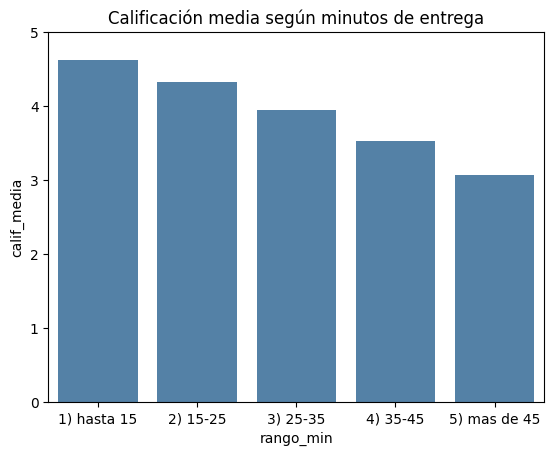

   correlacion
0        -0.54


In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

q1 = con.sql("""
    SELECT CASE WHEN tiempo_entrega_min <= 15 THEN '1) hasta 15'
                WHEN tiempo_entrega_min <= 25 THEN '2) 15-25'
                WHEN tiempo_entrega_min <= 35 THEN '3) 25-35'
                WHEN tiempo_entrega_min <= 45 THEN '4) 35-45'
                ELSE '5) mas de 45' END AS rango_min,
           COUNT(*) AS pedidos,
           ROUND(AVG(calificacion), 2) AS calif_media
    FROM plata_pedidos
    WHERE estado = 'entregado' AND calificacion IS NOT NULL AND tiempo_entrega_min IS NOT NULL
    GROUP BY 1
    ORDER BY 1
""").df()
display(q1)

sns.barplot(data=q1, x="rango_min", y="calif_media", color="steelblue")
plt.title("Calificación media según minutos de entrega")
plt.ylim(0, 5)
plt.show()

print(con.sql("""
    SELECT ROUND(corr(tiempo_entrega_min, calificacion), 2) AS correlacion
    FROM plata_pedidos
    WHERE estado = 'entregado' AND calificacion IS NOT NULL AND tiempo_entrega_min IS NOT NULL
""").df())

,zona_entrega,pedidos,tiempo_medio,calif_media,pct_mas_de_35min
0,Quillacollo,3613,39.8,3.52,70.0
1,Sacaba,4543,38.3,3.58,64.0
2,Tiquipaya,4102,30.6,3.90,32.0
3,Centro,7250,24.3,4.15,13.0
4,Pacata,3139,22.0,4.23,6.0
5,Muyurina,3647,21.6,4.24,7.0
6,Temporal,3147,21.3,4.24,6.0
7,Cala Cala,5531,20.6,4.27,5.0
8,Tupuraya,4126,21.0,4.28,6.0
9,Sarco,4163,20.7,4.29,6.0


,zona_entrega,rapido,lento
0,Quillacollo,4.00,3.31
1,Sacaba,4.03,3.32
2,Tiquipaya,4.12,3.44
3,Centro,4.26,3.45
4,Cala Cala,4.32,3.46
5,Pacata,4.28,3.49
6,Temporal,4.29,3.51
7,Muyurina,4.30,3.53
8,Queru Queru,4.34,3.53
9,Sarco,4.33,3.58


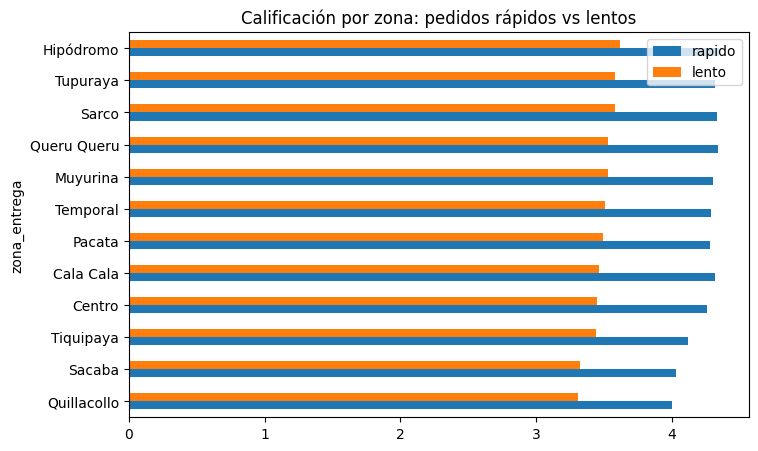

In [31]:
q2 = con.sql("""
    SELECT zona_entrega,
           COUNT(*) AS pedidos,
           ROUND(AVG(tiempo_entrega_min), 1) AS tiempo_medio,
           ROUND(AVG(calificacion), 2) AS calif_media,
           ROUND(100 * AVG((tiempo_entrega_min > 35)::INT), 0) AS pct_mas_de_35min
    FROM plata_pedidos
    WHERE estado = 'entregado' AND calificacion IS NOT NULL AND tiempo_entrega_min IS NOT NULL
    GROUP BY 1
    ORDER BY calif_media
""").df()
display(q2)

q3 = con.sql("""
    SELECT zona_entrega,
           ROUND(AVG(calificacion) FILTER (WHERE tiempo_entrega_min <= 35), 2) AS rapido,
           ROUND(AVG(calificacion) FILTER (WHERE tiempo_entrega_min > 35), 2) AS lento
    FROM plata_pedidos
    WHERE estado = 'entregado' AND calificacion IS NOT NULL AND tiempo_entrega_min IS NOT NULL
    GROUP BY 1
    ORDER BY lento
""").df()
display(q3)

q3.set_index("zona_entrega").plot.barh(figsize=(8, 5))
plt.title("Calificación por zona: pedidos rápidos vs lentos")
plt.show()

In [32]:
q4 = con.sql("""
    WITH r AS (
        SELECT rider_id, AVG(calificacion) AS c
        FROM plata_pedidos
        WHERE estado = 'entregado' AND calificacion IS NOT NULL AND tiempo_entrega_min <= 35
          AND rider_id IS NOT NULL
        GROUP BY 1 HAVING COUNT(*) >= 100
    ), s AS (
        SELECT cod_rest, AVG(calificacion) AS c
        FROM plata_pedidos
        WHERE estado = 'entregado' AND calificacion IS NOT NULL AND tiempo_entrega_min <= 35
        GROUP BY 1 HAVING COUNT(*) >= 100
    )
    SELECT 'riders' AS grupo, ROUND(MIN(c), 2) AS peor, ROUND(MAX(c), 2) AS mejor FROM r
    UNION ALL
    SELECT 'restaurantes', ROUND(MIN(c), 2), ROUND(MAX(c), 2) FROM s
""").df()
display(q4)

,grupo,peor,mejor
0,riders,4.14,4.40
1,restaurantes,4.07,4.34


In [33]:
print(con.sql("""
    SELECT tiempo_entrega_min > 35 AS mas_de_35_min,
           COUNT(*) AS pedidos,
           ROUND(AVG(calificacion), 2) AS calif_media
    FROM plata_pedidos
    WHERE estado = 'entregado' AND calificacion IS NOT NULL AND tiempo_entrega_min IS NOT NULL
    GROUP BY 1
""").df())

print(con.sql("""
    SELECT ROUND(100 * AVG((calificacion IS NULL)::INT), 0) AS pct_sin_calificar
    FROM plata_pedidos
    WHERE estado = 'entregado'
""").df())

   mas_de_35_min  pedidos  calif_media
0           True     9653         3.39
1          False    41903         4.28
   pct_sin_calificar
0               28.0


## P4. ¿Por qué nos califican mal?

### Número clave
Los pedidos que tardan más de 35 minutos promedian 3,39 estrellas y los demás 4,28 una diferencia de unas 0,9 estrellas
La correlación entre tiempo y calificación es -0,54.

### Frase para Valeria
Los pedidos que tardan más de 35 minutos reciben unas 0,9 estrellas menos, el problema es el tiempo y no la zona,
porque en todas las zonas el pedido lento califica peor, pero en Quillacollo y Sacaba el 70 % y el 64 % de los pedidos
pasan de 35 minutos, bajar el tiempo de entrega en esas dos zonas es lo que más ayudaría a subir la calificación.

### Lo que los datos no permiten concluir
Cerca de 3 de cada 10 pedidos entregados no tienen calificación, así que puede haber sesgo.

### Abogado del diablo
Mi conclusión: los pedidos de más de 35 minutos califican unas 0,9 estrellas menos y bajar el tiempo en Quillacollo y Sacaba ayudaría.

Riesgos que me dio la IA:
1. La calificación es opcional y 28 % no califica. Quien califica puede ser el cliente más molesto, así que la nota media podría estar sesgada.
2. Que el tiempo y la nota vayan juntos no prueba que el tiempo sea la causa. Puede haber otra cosa, como la hora pico o la lluvia, que alargue la entrega y a la vez moleste al cliente.
3. El corte de 35 minutos y la conversión de septiembre (de 1 a 10 a 1 a 5) son decisiones nuestras y podrían mover los números.

Qué hice con eso: agregué las dos primeras como limitaciones en la sección de arriba. Sobre el riesgo 3, comprobé que sin septiembre los promedios casi no cambian y que la nota baja de forma gradual por rangos de minutos así que no depende del corte de 35